# Chapter 12 · Project: the same twin in New York (winter 2023–24)
**Level: Expert** · ~30 min to read · first run ~90 min, then cached · 2D · *Applied project, part 6*

Chapters 10 and 11 were built on Gothenburg in summer: 358 links, convective storms, a weak
radar. Here the same code, with the same settings, goes to New York City in winter:

| letter | sensor | what it sees | count |
|---|---|---|---|
| **L** | commercial microwave links (OpenMesh), FieldSense RNN retrieval | path-averaged rain | 26 |
| **P** | personal weather stations, after quality control | rain in a bucket | 27 cells |
| **R** | MRMS radar | rain rate on 2 km cells | 1600 cells |
| | 4 airport gauges (ASOS: EWR, JFK, LGA, Central Park) | **never assimilated**: they only score | 4 |

Nothing is tuned for the new city. The cube is FieldSense's, read by `raintwin.cube.Cube`; its
240 km grid is cropped to the 80 km box around the sensors (`cube.WINDOWS`), which is about
the size of Gothenburg's grid. The 10 storms are FieldSense's study storms for New York, all
in the test weeks, from 21 November 2023 to 4 April 2024. Mostly wide winter rain.

**Questions**
1. Does the ranking of maps from Gothenburg hold in New York?
2. Does the twin still help, and where does it fail?
3. Is a student trained on the twin still a good map?

In [1]:
import sys, time, pickle; sys.path.insert(0, "..")
from pathlib import Path
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from dtwin import viz
from raintwin import system, distill
from raintwin.cube import Cube
viz.set_style()

CACHE = Path("../cache"); CACHE.mkdir(exist_ok=True)
c = Cube("openmesh")
EVENTS = c.events()
GI = np.round(c.gauges["y"] / c.dx).astype(int), np.round(c.gauges["x"] / c.dx).astype(int)
print(f"{len(c.times)} steps of 5 min (wet days only), {c.y.size} x {c.x.size} cells of {c.dx:.0f} km")
print(f"{len(c.link_id)} links, {len(c.pws['x'])} station cells, gauges {', '.join(c.gauges['id'])}")
print("split (train / validation / test steps):", np.bincount(c.split))

/Users/drorjac/PycharmProjects/pinn_digital_twins/notebooks/../raintwin/cube.py:61: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  self._link_rain = (lr.rnn.isel(link=np.flatnonzero(inside)).reindex(time=self.times)


10115 steps of 5 min (wet days only), 40 x 40 cells of 2 km
26 links, 27 station cells, gauges EWR, JFK, LGA, NYC
split (train / validation / test steps): [4085 1366 4664]


/Users/drorjac/PycharmProjects/pinn_digital_twins/notebooks/../raintwin/cube.py:75: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  self._gauge = g.g5.reindex(time=self.times).transpose("time", "station").values


## 1. The network

     nearest link [km]  nearest station [km]
EWR               14.1                  12.4
JFK               13.6                   9.7
LGA                7.1                   2.5
NYC                4.4                   0.2


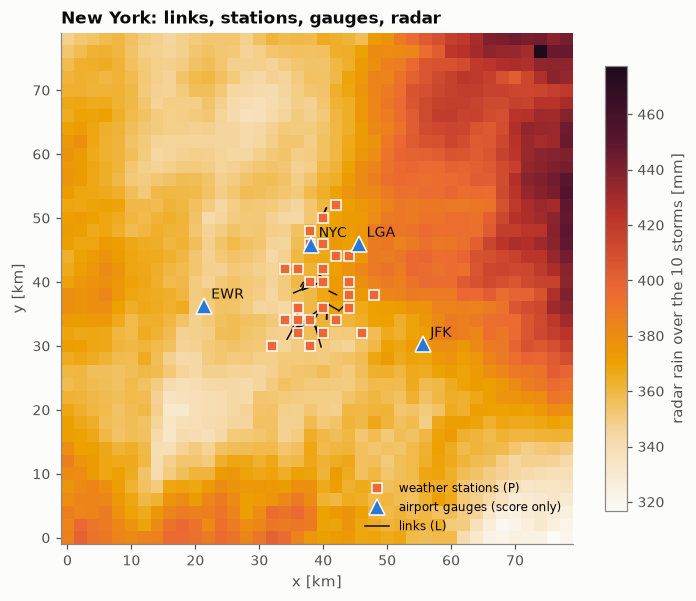

In [2]:
L = c.links
s = np.linspace(0, 1, 11)[:, None]
vx, vy = (L["xa"] + s * (L["xb"] - L["xa"])).ravel(), (L["ya"] + s * (L["yb"] - L["ya"])).ravel()
dist = pd.DataFrame({
    "nearest link [km]": [np.hypot(vx - x, vy - y).min() for x, y in zip(c.gauges["x"], c.gauges["y"])],
    "nearest station [km]": [np.hypot(c.pws["x"] - x, c.pws["y"] - y).min() for x, y in zip(c.gauges["x"], c.gauges["y"])],
}, index=c.gauges["id"])
print(dist.round(1).to_string())

tot = sum(np.nansum(c.radar(c.index(s, e)), 0) for _, s, e in EVENTS) / 12
ext = (-1, c.x[-1] + 1, -1, c.y[-1] + 1)
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.grid(False)
im = ax.imshow(tot, origin="lower", cmap=viz.FIELD, extent=ext)
plt.colorbar(im, ax=ax, shrink=0.7, label="radar rain over the 10 storms [mm]")
for i in range(L["xa"].size):
    ax.plot([L["xa"][i], L["xb"][i]], [L["ya"][i], L["yb"][i]], color=viz.INK, lw=1)
ax.plot(c.pws["x"], c.pws["y"], "s", color=viz.ORANGE, ms=6, mec="white", label="weather stations (P)")
ax.plot(c.gauges["x"], c.gauges["y"], "^", color=viz.BLUE, ms=10, mec="white", label="airport gauges (score only)")
for g, x, y in zip(c.gauges["id"], c.gauges["x"], c.gauges["y"]):
    ax.annotate(g, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=9, color=viz.INK)
ax.plot([], [], color=viz.INK, lw=1, label="links (L)")
ax.set(xlabel="x [km]", ylabel="y [km]", title="New York: links, stations, gauges, radar")
ax.legend(loc="lower right", fontsize=8)
viz.save(fig, "12_network.png")
plt.show()

The opposite of Gothenburg. There, every gauge was a few km from a link. Here the 26 links sit
in a 10 by 20 km strip of Manhattan, Brooklyn and Queens; Central Park and LaGuardia are 4 and
7 km from the nearest link, Newark and JFK 14 km. Central Park has a station 200 m away. So the
score here asks a different question: how well does each map reach *away* from its sensors?

## 2. Scoring rule and the static maps
Same rule as Chapter 10: each map is read at the gauge's cell, summed to hourly rain and
compared with the gauge; NRMSE is the RMSE divided by the mean gauge rain. The ASOS records
have gaps (Central Park is missing in three storms, Newark in parts of most), and an hour only
counts when all 12 of its 5-min values are there.

In [3]:
SPIN = 12
steps = [c.index(s - pd.Timedelta("1h"), e) for _, s, e in EVENTS]
ti = np.concatenate([st[SPIN:] for st in steps])
G = c.gauge_rain(ti)
HOURS = c.times[ti].ceil("h")


def hourly(a):
    return pd.DataFrame(a / 12, index=HOURS).groupby(level=0).sum(min_count=12).values


GH = hourly(G)
print("gauge hours scored:", ", ".join(f"{g} {n}" for g, n in zip(c.gauges["id"], np.isfinite(GH).sum(0))))


def score(E):
    Eh = hourly(E)
    ok, ok5 = np.isfinite(Eh) & np.isfinite(GH), np.isfinite(E) & np.isfinite(G)
    return dict(nrmse=np.sqrt(np.mean((Eh[ok] - GH[ok]) ** 2)) / GH[ok].mean(),
                corr=np.corrcoef(Eh[ok], GH[ok])[0, 1], bias=Eh[ok].mean() / GH[ok].mean() - 1,
                corr5=np.corrcoef(E[ok5], G[ok5])[0, 1])


def per_gauge(E):
    Eh = hourly(E)
    out = []
    for j in range(GH.shape[1]):
        ok = np.isfinite(Eh[:, j]) & np.isfinite(GH[:, j])
        out.append(np.sqrt(np.mean((Eh[ok, j] - GH[ok, j]) ** 2)) / GH[ok, j].mean())
    return out


at_gauges = {p: c.product(p, ti)[:, GI[0], GI[1]] for p in ("R", "C", "P", "CP", "RC", "RP", "RCP")}
table = {f"static {p}": score(E) for p, E in at_gauges.items()}
print(pd.DataFrame(table).T.round(2).to_string())

gauge hours scored: EWR 103, JFK 173, LGA 193, NYC 116


            nrmse  corr  bias  corr5
static R     0.83  0.85 -0.27   0.66
static C     0.97  0.70 -0.22   0.46
static P     0.55  0.93  0.14   0.69
static CP    0.58  0.90 -0.01   0.69
static RC    0.90  0.76 -0.23   0.50
static RP    0.49  0.95  0.19   0.73
static RCP   0.43  0.95  0.11   0.74


Gothenburg's order turns over. There the radar was the worst map (1.47) and the links the best
single sensor (1.07). Here the radar alone is good (0.83) and the links are the weakest (0.97,
and 22 % low). The stations are the best single sensor (0.55), and the radar adjusted by
stations and links (RCP, 0.43) is the best map in both cities.

## 3. The twin, same settings as Gothenburg

In [4]:
CONFIGS = ["L", "P", "R", "LP", "LR", "LPR"]
FIG_EVENT = "20240323T06"


def run_all():
    out = {}
    for cf in CONFIGS:
        t0 = time.time()
        g_mean, g_now, vel, maps = [], [], [], None
        for (name, _, _), st in zip(EVENTS, steps):
            o = system.run(c, st, cf)
            g_mean.append(o["mean"][SPIN:][:, GI[0], GI[1]]); g_now.append(o["now"][SPIN:][:, GI[0], GI[1]])
            vel.append(o["V"])
            if name == FIG_EVENT and cf in ("L", "LPR"):
                maps = {k: o[k].astype("float32") for k in o if k != "V"}
        out[cf] = dict(mean=np.concatenate(g_mean), now=np.concatenate(g_now), V=vel, maps=maps,
                       seconds=time.time() - t0)
        print(f"{cf:4s}: {time.time() - t0:4.0f}s")
    return out


f = CACHE / "ch12_runs.pkl"
if f.exists():
    runs = pickle.load(open(f, "rb"))
else:
    runs = run_all()
    pickle.dump(runs, open(f, "wb"))
for cf, r in runs.items():
    table[f"twin {cf} (mean)"] = score(r["mean"])
    table[f"twin {cf} (now map)"] = score(r["now"])
T = pd.DataFrame(table).T
print(T.round(2).to_string())

                    nrmse  corr  bias  corr5
static R             0.83  0.85 -0.27   0.66
static C             0.97  0.70 -0.22   0.46
static P             0.55  0.93  0.14   0.69
static CP            0.58  0.90 -0.01   0.69
static RC            0.90  0.76 -0.23   0.50
static RP            0.49  0.95  0.19   0.73
static RCP           0.43  0.95  0.11   0.74
twin L (mean)        1.43  0.26 -0.67   0.20
twin L (now map)     1.43  0.26 -0.67   0.20
twin P (mean)        1.04  0.67 -0.38   0.56
twin P (now map)     0.96  0.71 -0.12   0.55
twin R (mean)        0.91  0.86 -0.34   0.72
twin R (now map)     0.91  0.86 -0.34   0.72
twin LP (mean)       1.17  0.66 -0.58   0.53
twin LP (now map)    1.01  0.69 -0.29   0.53
twin LR (mean)       0.83  0.84 -0.19   0.70
twin LR (now map)    0.83  0.84 -0.19   0.70
twin LPR (mean)      0.78  0.86 -0.20   0.72
twin LPR (now map)   0.58  0.90  0.07   0.70


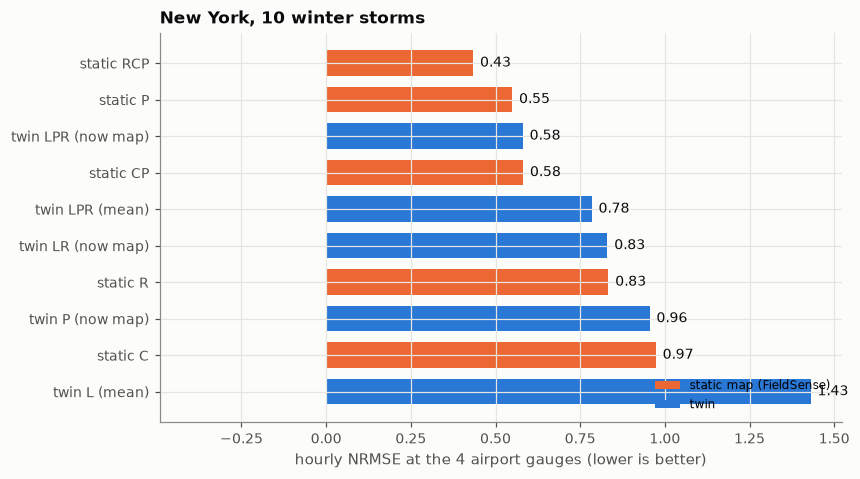

In [5]:
show = ["static R", "static C", "static P", "static CP", "static RCP", "twin L (mean)",
        "twin P (now map)", "twin LR (now map)", "twin LPR (mean)", "twin LPR (now map)"]
order = T.loc[show].sort_values("nrmse")
cols = [viz.ORANGE if "static" in k else viz.TWIN for k in order.index]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(range(len(order)), order.nrmse, color=cols, height=0.7)
ax.set_yticks(range(len(order)), order.index)
ax.invert_yaxis()
for i, v in enumerate(order.nrmse):
    ax.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=9, color=viz.INK)
ax.bar(0, 0, color=viz.ORANGE, label="static map (FieldSense)"); ax.bar(0, 0, color=viz.TWIN, label="twin")
ax.legend(loc="lower right", fontsize=8)
ax.set(xlabel="hourly NRMSE at the 4 airport gauges (lower is better)", title="New York, 10 winter storms")
viz.save(fig, "12_scores.png")
plt.show()

* With all sensors, the twin's now map (0.58) ties the IDW of links and stations (CP, 0.58) and
  is clearly behind RCP (0.43).
* The links-only twin fails: 1.43, 67 % low, correlation 0.26. IDW of the same links scores
  0.97. This is the one result that is much worse than in Gothenburg (1.15 there).

Why the links-only twin fails is clearest gauge by gauge:

In [6]:
rows = {k: per_gauge(at_gauges[k.split()[1]]) for k in ["static R", "static C", "static P", "static CP", "static RCP"]}
rows["twin L (mean)"] = per_gauge(runs["L"]["mean"])
rows["twin LPR (mean)"] = per_gauge(runs["LPR"]["mean"])
rows["twin LPR (now map)"] = per_gauge(runs["LPR"]["now"])
PG = pd.DataFrame(rows, index=c.gauges["id"]).T
PG.columns = [f"{g} ({d:.0f} km)" for g, d in zip(c.gauges["id"], dist["nearest link [km]"])]
print("hourly NRMSE per gauge (distance to the nearest link):")
print(PG.round(2).to_string())

hourly NRMSE per gauge (distance to the nearest link):
                    EWR (14 km)  JFK (14 km)  LGA (7 km)  NYC (4 km)
static R                   0.85         0.73        0.84        0.93
static C                   1.00         0.86        0.97        1.07
static P                   0.91         0.60        0.38        0.45
static CP                  0.85         0.64        0.51        0.37
static RCP                 0.59         0.45        0.34        0.45
twin L (mean)              1.52         1.40        1.46        1.34
twin LPR (mean)            0.82         0.71        0.72        0.94
twin LPR (now map)         0.82         0.71        0.39        0.46


Every gauge is 4 km or more from a link, outside the reach of a link's update. Beyond that the
twin has only what the wind carries in, and between storms its field decays to the 0.1 mm/h
background. IDW does the opposite: it copies the nearest link's value to any distance. In
summer showers that is wrong; in wide winter rain it is close to right. Making the twin reach
further does not save it. I tried a 30 km localisation radius instead of 15, 12 km noise
instead of 6, and a 6 h memory instead of 2 h: the links-only twin stayed between 1.35 and 1.40
(and over 5 with the long memory, which keeps rain long after it has stopped).

The now map's correction from the stations works where there is a station: at LaGuardia and
Central Park the twin's LPR error drops from 0.72 and 0.94 to 0.39 and 0.46. At Newark and JFK
it changes nothing, and RCP is better there (0.59 and 0.45 against 0.82 and 0.71). RCP corrects
the radar with one adjustment field that reaches across the whole city; the twin's corrections
stay within 15 km of a sensor.

## 4. A winter storm in the twin

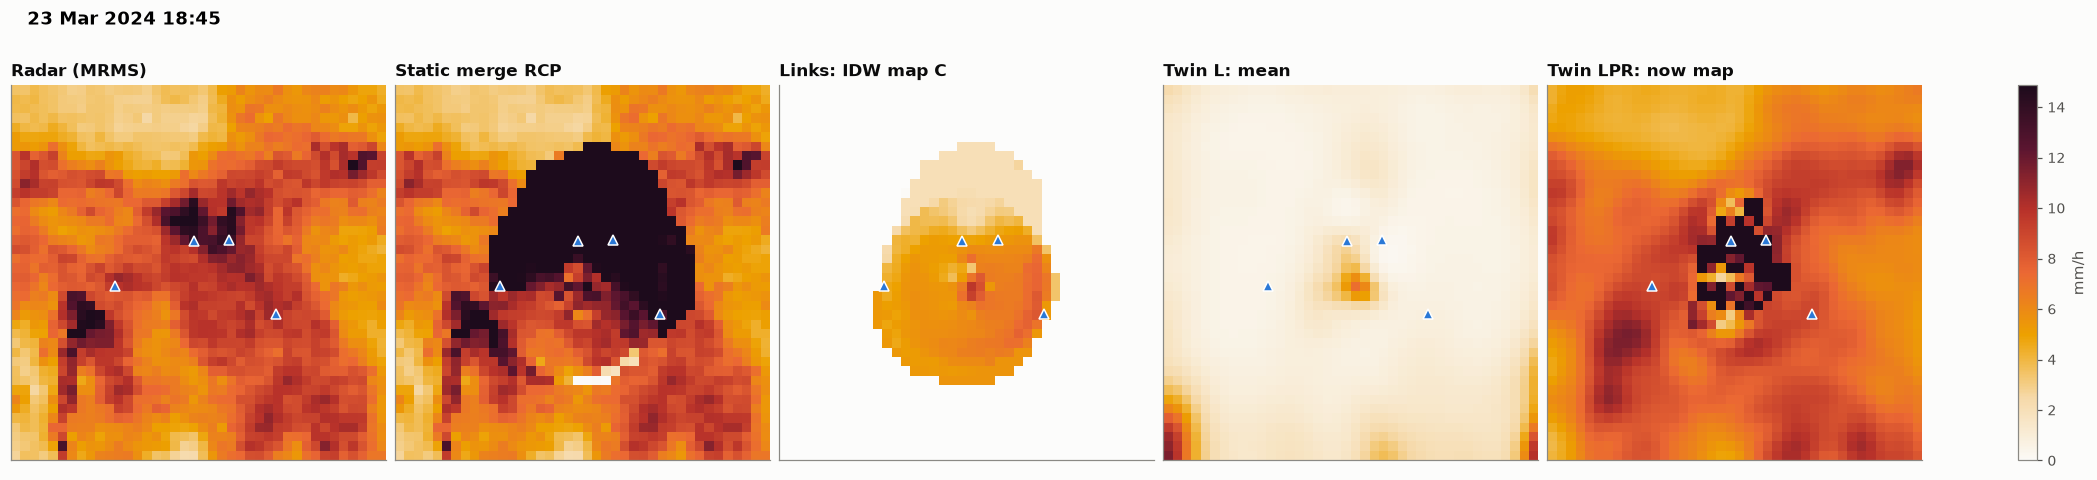

In [7]:
fe = [i for i, (n, _, _) in enumerate(EVENTS) if n == FIG_EVENT][0]
st = steps[fe]
k = int(np.nanargmax(np.nanmean(c.radar(st), (1, 2))))
rL, r = runs["L"]["maps"], runs["LPR"]["maps"]
fields = [(np.nan_to_num(c.radar(st[[k]])[0]), "Radar (MRMS)", viz.FIELD),
          (c.product("RCP", st[[k]])[0], "Static merge RCP", viz.FIELD),
          (c.product("C", st[[k]])[0], "Links: IDW map C", viz.FIELD),
          (rL["mean"][k], "Twin L: mean", viz.FIELD),
          (r["now"][k], "Twin LPR: now map", viz.FIELD)]
vm = np.nanpercentile(fields[0][0], 99.5)
fig, axes = plt.subplots(1, 5, figsize=(19, 4.6), constrained_layout=True)
for ax, (F, ttl, cm) in zip(axes, fields):
    ax.grid(False)
    im = ax.imshow(F, origin="lower", cmap=cm, vmin=0, vmax=vm, extent=ext)
    ax.plot(c.gauges["x"], c.gauges["y"], "^", color=viz.BLUE, ms=6, mec="white")
    ax.set(title=ttl, xticks=[], yticks=[])
plt.colorbar(im, ax=axes, shrink=0.8, label="mm/h")
fig.suptitle(f"{c.times[st[k]]:%d %b %Y %H:%M}", x=0.01, ha="left", fontweight="bold")
viz.save(fig, "12_maps.png")
plt.show()

The links-only twin has rain over the links and little elsewhere. The link IDW spreads the
same values over the whole box, which in this storm is closer to the radar. With the radar in
it, the twin has the whole storm.

**Motion.** The twin's velocity at the end of each storm:

In [8]:
for cf in ("L", "LPR"):
    sp = [np.hypot(*v[-1]) for v in runs[cf]["V"]]
    print(f"twin {cf:4s}: end-of-storm speed {np.median(sp):.0f} km/h median "
          f"(range {np.min(sp):.0f} to {np.max(sp):.0f})")

twin L   : end-of-storm speed 8 km/h median (range 2 to 24)
twin LPR : end-of-storm speed 9 km/h median (range 4 to 28)


Slow: 8 to 9 km/h, where winter storms over New York usually move at several tens of km/h. The
twin was slow in Gothenburg too (Chapter 10). With rain covering the whole box, a small shift
barely changes the readings, so the links and stations give the velocity little to learn from.

## 5. Distillation in New York
Same as Chapter 11: a 216 k-weight U-Net sees only the link and station maps (C, P and where
each has data, at t, t-5 and t-10 min) and learns a teacher's map. The teacher runs over the
wet periods of the training and validation weeks (`tools/teacher_labels.py openmesh`). New
York's cube keeps only wet days, so a period also ends at every jump in the clock. Two seeds for
the twin and RCP teachers, one for the radar.

In [9]:
f = CACHE / "teacher_openmesh.npz"
if not f.exists():
    wins = system.wet_windows(c)
    parts = [system.run(c, w, "LPR") for w in wins]
    np.savez_compressed(f, idx=np.concatenate(wins),
                        now=np.concatenate([p["now"] for p in parts]).astype("float16"),
                        spread=np.concatenate([p["spread"] for p in parts]).astype("float16"),
                        window=np.concatenate([np.full(len(w), j) for j, w in enumerate(wins)]), sensors="LPR")
TE = np.load(f)
idx = TE["idx"]
tr, va = c.split[idx] == 0, c.split[idx] == 1
print(f"teacher: {len(idx)} wet steps in {len(np.unique(TE['window']))} periods; train {tr.sum()}, validation {va.sum()}")

X = distill.stack_inputs(c, idx)
targets = {"twin": np.stack([np.log1p(TE["now"].astype("float32")), np.log1p(TE["spread"].astype("float32"))], 1),
           "RCP": np.log1p(np.nan_to_num(c.product("RCP", idx)))[:, None].astype("float32"),
           "radar": np.log1p(np.nan_to_num(c.radar(idx)))[:, None].astype("float32")}
valid = np.isfinite(c.radar(idx))[:, None].astype("float32")
SEEDS = {"twin": [0, 1], "RCP": [0, 1], "radar": [0]}
COLOR = {"radar": viz.ORANGE, "RCP": viz.AQUA, "twin": viz.TWIN}
nets = {}
for name, seeds in SEEDS.items():
    Y = targets[name]
    M = None if name == "twin" else valid
    for sd in seeds:
        fw = CACHE / f"ch12_{name}_s{sd}.pt"
        net = distill.Student(X.shape[1], Y.shape[1])
        if fw.exists():
            saved = torch.load(fw, weights_only=False)
            net.load_state_dict(saved["state"]); net.history = saved["history"]
        else:
            t0 = time.time()
            net = distill.train(X[tr], Y[tr], None if M is None else M[tr], X[va], Y[va],
                                None if M is None else M[va], epochs=25, seed=sd, log=lambda m: None)
            torch.save({"state": net.state_dict(), "history": net.history}, fw)
            print(f"{name} seed {sd}: {time.time() - t0:.0f}s")
        nets[(name, sd)] = net
del X, targets

teacher: 4400 wet steps in 39 periods; train 3389, validation 1011


In [10]:
Xt = distill.stack_inputs(c, ti)
rows = {"static CP (same inputs)": score(at_gauges["CP"]), "static RCP": score(at_gauges["RCP"]),
        "teacher: twin LPR now map": score(runs["LPR"]["now"])}
for (name, sd), net in nets.items():
    out = distill.predict(net, Xt)[:, 0][:, GI[0], GI[1]]
    rows[f"student <- {name}, seed {sd}"] = score(out)
S = pd.DataFrame(rows).T
print(S.round(3).to_string())

                           nrmse   corr   bias  corr5
static CP (same inputs)    0.582  0.897 -0.008  0.687
static RCP                 0.434  0.949  0.115  0.743
teacher: twin LPR now map  0.581  0.898  0.073  0.697
student <- twin, seed 0    0.835  0.848 -0.272  0.692
student <- twin, seed 1    0.824  0.862 -0.247  0.700
student <- RCP, seed 0     0.560  0.910 -0.046  0.717
student <- RCP, seed 1     0.567  0.902  0.047  0.690
student <- radar, seed 0   0.904  0.900 -0.389  0.728


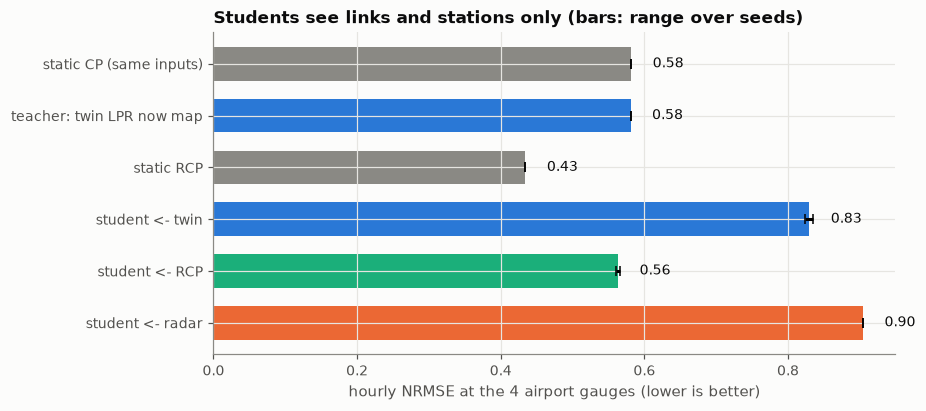

In [11]:
labels = ["static CP (same inputs)", "teacher: twin LPR now map", "static RCP"] + \
         [f"student <- {n}" for n in SEEDS]
vals, errs, cols = [], [], []
for lab in labels:
    if lab.startswith("student"):
        n = lab.split("<- ")[1]
        v = S.loc[[f"student <- {n}, seed {sd}" for sd in SEEDS[n]], "nrmse"]
        vals.append(v.mean()); errs.append([v.mean() - v.min(), v.max() - v.mean()]); cols.append(COLOR[n])
    else:
        vals.append(S.loc[lab, "nrmse"]); errs.append([0, 0]); cols.append(viz.MUTED if "CP" in lab else
                                                                        (viz.TWIN if "twin" in lab else viz.AQUA))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(range(len(vals)), vals, xerr=np.array(errs).T, color=cols, height=0.65, capsize=3)
ax.set_yticks(range(len(vals)), labels)
ax.invert_yaxis()
for i, v in enumerate(vals):
    ax.text(v + 0.03, i, f"{v:.2f}", va="center", fontsize=9, color=viz.INK)
ax.set(xlabel="hourly NRMSE at the 4 airport gauges (lower is better)",
       title="Students see links and stations only (bars: range over seeds)")
viz.save(fig, "12_students.png")
plt.show()

Chapter 11's result does not transfer. In Gothenburg the twin was the best teacher (1.02); here
its students are the weakest after the radar's (about 0.83, and 25 % low at every gauge), well
behind their own teacher (0.58). The RCP students are the best students (0.56 and 0.57).

The reason is what the teacher knows that the student cannot see. In Gothenburg the radar was
weak and the twin's map came mostly from the links, which the student also sees. In New York
the radar is good and carries the twin's map away from the 26 links; a student without radar
can only guess that part, and a guess trained on log(1 + R) errs low. The radar student, which
has to guess everything, is 39 % low. The RCP map is pinned to the stations, and the stations
are inputs, so more of it can be learned. Its validation loss is still the higher one; but the
gauges sit next to stations, not in the radar-only parts.

I also tried rescaling each student so that its mean over the validation weeks matches its
teacher's. It helps the twin students (0.66 and 0.69) and ruins the RCP students (1.33): the
level a student misses in the validation weeks is not the level it misses in the test storms.


## 6. The radar's bias, unfrozen
Chapter 13 found a bug in this twin. The radar's log-bias b is part of the state, but nothing
makes it move between updates: it has no process noise. At the first update hundreds of radar
cells collapse its ensemble spread, and from then on it stays where it landed.
`tools/bias_fix_runs.py` reruns the ten storms with the two fixes of Chapter 13: a random walk
on the bias (`q_bias=0.02` per 5 min, like the one on the velocity), and the stations observed
in log space (`point_log`). A `+b` mix has only the first fix, a `+` mix has both (P has no
radar, so P+ has only the second). The cell checks first that the rerun of the plain LPR twin is
identical to the run in section 3.

In [12]:
NET, FIG_PREFIX = "openmesh", "12"

                       nrmse   corr   bias  corr5
twin LPR (mean map)    0.784  0.862 -0.196  0.722
twin LPR (now map)     0.581  0.898  0.073  0.697
twin LPR+b (mean map)  1.235  0.785 -0.625  0.660
twin LPR+b (now map)   0.844  0.786 -0.182  0.613
twin LPR+ (mean map)   1.002  0.847 -0.463  0.719
twin LPR+ (now map)    0.791  0.810 -0.197  0.626
twin LR (mean map)     0.831  0.840 -0.186  0.700
twin LR (now map)      0.831  0.840 -0.186  0.700
twin LR+ (mean map)    1.252  0.740 -0.615  0.627
twin LR+ (now map)     1.252  0.740 -0.615  0.627
twin P (mean map)      1.042  0.673 -0.377  0.559
twin P (now map)       0.955  0.706 -0.117  0.546
twin P+ (mean map)     0.949  0.697 -0.099  0.585
twin P+ (now map)      0.943  0.709 -0.016  0.544
radar / gauges per storm: 1.51 1.21 1.22 0.72 1.22 0.96 0.96 0.76 0.75 0.89
radar factor, LPR  : range within storms 0.82 to 0.89, at the end 0.84 (median)
radar factor, LPR+b: range within storms 0.83 to 2.55, at the end 0.96 (median)


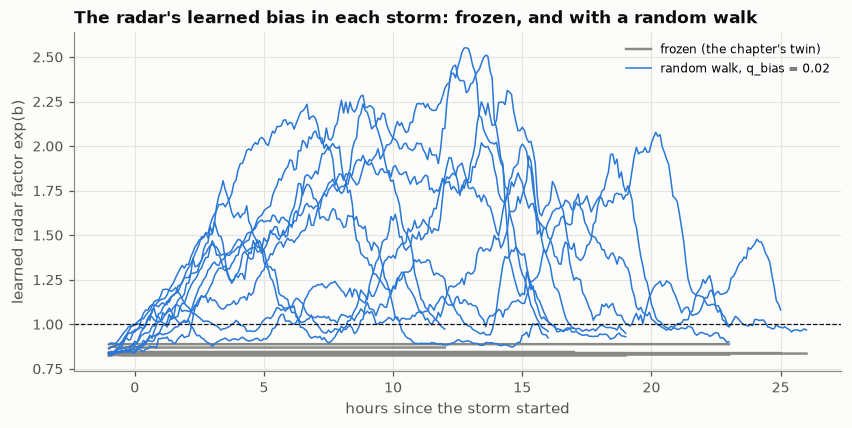

In [13]:
FIX = CACHE / "fix"
FIX_MIXES = ["LPR", "LPR+b", "LPR+", "LR+", "P+"]
assert all((FIX / f"{NET}_{m}_{n}.npz").exists() for m in FIX_MIXES for n, _, _ in EVENTS), \
    "run python tools/bias_fix_runs.py first"
fix = {m: [np.load(FIX / f"{NET}_{m}_{n}.npz") for n, _, _ in EVENTS] for m in FIX_MIXES}
assert np.allclose(np.concatenate([d["now"] for d in fix["LPR"]]), runs["LPR"]["now"], equal_nan=True)
fix_table = {}
for base, fixed in [("LPR", ["LPR+b", "LPR+"]), ("LR", ["LR+"]), ("P", ["P+"])]:
    for m in [base] + fixed:
        for k in ("mean", "now"):
            g = runs[base][k] if m == base else np.concatenate([d[k] for d in fix[m]])
            fix_table[f"twin {m} ({k} map)"] = score(g)
print(pd.DataFrame(fix_table).T.round(3).to_string())
ratio = [np.nansum(c.product("R", st[SPIN:])[:, GI[0], GI[1]]) / np.nansum(c.gauge_rain(st[SPIN:])) for st in steps]
print("radar / gauges per storm:", " ".join(f"{r:.2f}" for r in ratio))
for m in ("LPR", "LPR+b"):
    f = [d["radar_factor"] for d in fix[m]]
    print(f"radar factor, {m:5s}: range within storms {min(x.min() for x in f):.2f} to {max(x.max() for x in f):.2f}, "
          f"at the end {np.median([x[-1] for x in f]):.2f} (median)")

fig, ax = plt.subplots(figsize=(9, 4))
for j, m in enumerate(("LPR", "LPR+b")):
    for i, d in enumerate(fix[m]):
        h = np.arange(d["radar_factor"].size) / 12 - 1
        ax.plot(h, d["radar_factor"], color=(viz.MUTED, viz.TWIN)[j], lw=(1.6, 1.0)[j],
                label=(None if i else ("frozen (the chapter's twin)", "random walk, q_bias = 0.02")[j]))
ax.axhline(1, color=viz.INK, lw=0.8, ls="--")
ax.set(xlabel="hours since the storm started", ylabel="learned radar factor exp(b)",
       title="The radar's learned bias in each storm: frozen, and with a random walk")
ax.legend(fontsize=8)
viz.save(fig, f"{FIG_PREFIX}_bias.png")
plt.show()

**Reading the rerun.**
* The bias is frozen here too: 0.82 to 0.89, set at the first update.
* Unfrozen, it **runs off**. In every storm the factor climbs to 1.7 to 2.6 ("the radar reads
  twice too high"), while the MRMS radar reads 0.72 to 1.51 times the gauges per storm and 27 %
  low overall. The twin divides the radar by that factor and ends 52 to 71 % low. The full twin's now map falls from 0.58 to 0.84
  (0.79 with the stations in log space), and links + radar from 0.83 to 1.25.
* Stations in log space alone change little (P now map 0.95 to 0.94).

Why the difference from Gothenburg? A bias that may move can only be learned if something else
fixes the rain level. In Gothenburg 358 links in the scored area do that. Here the radar supplies
almost all the observations, and a few dozen links and stations spread over a 240 km box cannot
hold the level. The random walk adds a little uncertainty every 5 minutes; the radar alone
cannot tell a wetter field from a radar that reads high, so the bias drifts and nothing brings
it back.

So the numbers of this chapter stand, and Chapter 13's fix does not carry over. Here the frozen
bias, a fixed calibration of about 0.85, was the safer choice. A bias that is allowed to move
needs ground sensors that pin the level, or a pull back towards 1 (not tried here).

## Conclusions
* The ranking of maps flips with the city. In Gothenburg links were the best sensor and the
  radar the worst; in New York the stations are the best sensor and the radar alone beats the
  links. The radar merged with stations and links (RCP) is the best map in both.
* The same twin, untuned, ties IDW with all sensors (0.58) and is behind RCP (0.43). Near
  stations its now map is as good as RCP; far from every sensor it has only the radar.
* A links-only twin needs links near the place it is scored. With 26 links 4 to 14 km from the
  gauges it fails (1.43), where plain IDW of the same links holds up in wide winter rain. A
  longer localisation, larger noise or longer memory does not fix it.
* Distillation depends on what the teacher used that the student cannot see. A twin that leans
  on a good radar is a poor teacher for a radar-free student (0.83, 25 % low); on New York data,
  the merged product RCP is the better teacher (0.56 to 0.57).
* The radar's bias was frozen at its first estimate here too. Unfrozen (Chapter 13's fix), it
  runs off to twice its value and the full twin falls from 0.58 to 0.84: with few ground
  sensors the radar's bias cannot be told apart from the rain level.
* Four gauges, two of them far from everything, are a thin exam. Differences under about 0.05
  should not be read as real.

**Next.** Give the student the radar as an input (the teacher's lesson would then be how to
correct it), or score both cities at the stations by leaving each one out, as FieldSense does.